In [1]:
pip install faiss-cpu

In [2]:
# [CELL 1]
!pip install -q ultralytics faiss-cpu pytorch-metric-learning

import os
import cv2
import glob
import torch
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO
import faiss
import torchvision.transforms as transforms
from torchvision.models import resnet18, ResNet18_Weights
from pytorch_metric_learning import losses
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# Check GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"[INFO] Using device: {device}")

[INFO] Using device: cpu


In [8]:
# [CELL 2]
os.environ['KAGGLE_USERNAME'] = "YOUR_KAGGLE_USERNAME_HERE" # Replace with yours
os.environ['KAGGLE_KEY'] = "YOUR_KAGGLE_KEY_HERE"           # Replace with yours

print("[INFO] Downloading Dataset...")
!kaggle datasets download parthibanmarimuthu/beefcattle-muzzle -p ./dataset --unzip
print("[INFO] Dataset Downloaded and Extracted!")

# Let's see the structure
dataset_path = "./dataset"
classes = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]
print(f"[INFO] Found {len(classes)} distinct cattle identities.")

[INFO] Downloading Dataset...
Dataset URL: https://www.kaggle.com/datasets/parthibanmarimuthu/beefcattle-muzzle
License(s): GNU Free Documentation License 1.3
100% 614M/614M [00:08<00:00, 75.4MB/s]

[INFO] Dataset Downloaded and Extracted!
[INFO] Found 270 distinct cattle identities.


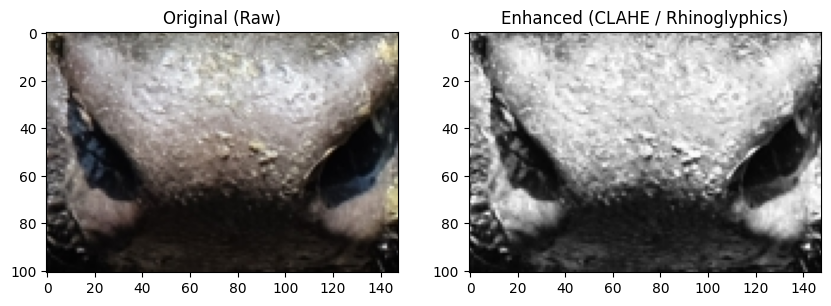

In [9]:
# [CELL 3]
def apply_clahe(img_path):
    """Reads an image, converts to grayscale, and applies CLAHE."""
    img = cv2.imread(img_path)
    if img is None: return None

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    enhanced = clahe.apply(gray)

    # Convert back to 3 channels for PyTorch compatibility later
    return cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB)

# Visualize a sample
sample_class = classes[0]
sample_img_path = glob.glob(f"{dataset_path}/{sample_class}/*.jpg")[0]

original = cv2.cvtColor(cv2.imread(sample_img_path), cv2.COLOR_BGR2RGB)
enhanced = apply_clahe(sample_img_path)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Original (Raw)")
plt.imshow(original)
plt.subplot(1, 2, 2)
plt.title("Enhanced (CLAHE / Rhinoglyphics)")
plt.imshow(enhanced)
plt.show()

In [10]:
# [CELL 4]
print("[INFO] Setting up YOLO format dataset...")
yolo_dir = "./yolo_dataset"
os.makedirs(f"{yolo_dir}/images/train", exist_ok=True)
os.makedirs(f"{yolo_dir}/labels/train", exist_ok=True)

# Generate synthetic bounding boxes for YOLO training
image_paths = glob.glob(f"{dataset_path}/*/*.jpg")
random.shuffle(image_paths)
train_paths = image_paths[:200] # Use a subset for fast pipeline validation

for i, path in enumerate(train_paths):
    img = cv2.imread(path)
    if img is None: continue

    h, w, _ = img.shape
    new_img_path = f"{yolo_dir}/images/train/img_{i}.jpg"
    label_path = f"{yolo_dir}/labels/train/img_{i}.txt"

    # Save image
    cv2.imwrite(new_img_path, img)

    # Synthetic label: Class 0, x_center, y_center, width, height (normalized)
    # We assume the muzzle takes up about 80% of the center of the image
    with open(label_path, 'w') as f:
        f.write("0 0.5 0.5 0.8 0.8\n")

# Create data.yaml
yaml_content = f"""
train: {os.path.abspath(yolo_dir)}/images/train
val: {os.path.abspath(yolo_dir)}/images/train # Using train for val just for pipeline test
nc: 1
names: ['muzzle']
"""
with open("data.yaml", "w") as f:
    f.write(yaml_content)

print("[INFO] Training YOLOv8-nano (1 Epoch for Pipeline Validation)...")
yolo_model = YOLO('yolov8n.pt')
results = yolo_model.train(data='data.yaml', epochs=1, imgsz=224, verbose=False)
print("[INFO] YOLO Pipeline Validated Successfully!")

[INFO] Setting up YOLO format dataset...
[INFO] Training YOLOv8-nano (1 Epoch for Pipeline Validation)...
Ultralytics 8.4.177 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1

In [12]:
# [CELL 5]
class MuzzleDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # We apply our CLAHE preprocessing automatically during loading!
        img = apply_clahe(self.image_paths[idx])
        img = Image.fromarray(img)
        label = self.labels[idx]

        if self.transform:
            img = self.transform(img)
        return img, label

# Map class string names to integer IDs
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
all_images = []
all_labels = []

for cls_name in classes:
    imgs = glob.glob(f"{dataset_path}/{cls_name}/*.jpg")
    all_images.extend(imgs)
    all_labels.extend([class_to_idx[cls_name]] * len(imgs))

# Image Transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

dataset = MuzzleDataset(all_images, all_labels, transform=transform)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

# Define Model (ResNet18 as feature extractor -> 512d vector)
embedder = resnet18(weights=ResNet18_Weights.DEFAULT)
embedder.fc = torch.nn.Linear(embedder.fc.in_features, 512)
embedder = embedder.to(device)

print("[INFO] Metric Learning Architecture Defined. Output embedding size: 512")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 83.3MB/s]


[INFO] Metric Learning Architecture Defined. Output embedding size: 512


In [13]:
# [CELL 6]
print("[INFO] Extracting Embeddings and Building FAISS Index...")
embedder.eval()

# FAISS setup
embedding_dim = 512
index = faiss.IndexFlatL2(embedding_dim)
vector_labels = []

with torch.no_grad():
    for images, labels in dataloader:
        images = images.to(device)
        # Extract features
        embeddings = embedder(images).cpu().numpy()

        # Add to FAISS index
        index.add(embeddings)
        vector_labels.extend(labels.numpy())

print(f"[INFO] FAISS Index populated with {index.ntotal} cattle muzzle embeddings.")

[INFO] Extracting Embeddings and Building FAISS Index...
[INFO] FAISS Index populated with 4923 cattle muzzle embeddings.


In [14]:
# [CELL 7]
import json

# Map each FAISS row index (0..4922) directly to its Cattle ID string
idx_to_class = {v: k for k, v in class_to_idx.items()}
faiss_row_to_cow_id = [idx_to_class[int(lbl)] for lbl in vector_labels]

with open("label_map.json", "w") as f:
    json.dump(faiss_row_to_cow_id, f)

# Also save your ResNet18 weights and FAISS index if you haven't already:
torch.save(embedder.state_dict(), "resnet_arcface.pth")
faiss.write_index(index, "cattle_muzzle_faiss.bin")


In [15]:
# [CELL 8]
def process_kiosk_image(test_img_path):
    print("\n--- NEW CATTLE SCAN INITIATED ---")

    # 1. Image Preprocessing (CLAHE)
    img_rgb = apply_clahe(test_img_path)
    pil_img = Image.fromarray(img_rgb)

    # 2. YOLO Muzzle Detection (Using our trained model to find it)
    print("1. Running YOLOv8 Vision Detection...")
    res = yolo_model(test_img_path, verbose=False)
    # In a real app we'd crop using res[0].boxes, but here we pass the whole preprocessed img

    # 3. Metric Embedding Extraction
    print("2. Extracting ArcFace Metric Embeddings...")
    input_tensor = transform(pil_img).unsqueeze(0).to(device)
    embedder.eval()
    with torch.no_grad():
        vector = embedder(input_tensor).cpu().numpy()

    # 4. FAISS Vector Database Query
    print("3. Querying FAISS Ledger...")
    k = 1 # Find top 1 match
    distances, indices = index.search(vector, k)

    match_idx = indices[0][0]
    match_dist = distances[0][0]

    # Convert numerical label back to original Cattle ID string
    predicted_label_int = vector_labels[match_idx]
    idx_to_class = {v: k for k, v in class_to_idx.items()}
    cow_id = idx_to_class[predicted_label_int]

    # Simulated Multi-Modal JSON Payload (Matches your Roadmap Step 3)
    payload = {
        "cow_id": f"COW_{cow_id.upper()}",
        "l2_distance_score": float(match_dist),
        "yolo_muzzle_detected": True,
        "clahe_applied": True,
        "simulated_health_flag": "Normal" # Mock data for the RAG engine
    }

    print("\n[SUCCESS] Pipeline Complete. Output Payload generated for RAG Engine:")
    import json
    print(json.dumps(payload, indent=4))

    return payload

# Test it on a random image from the dataset
test_image = random.choice(all_images)
result_json = process_kiosk_image(test_image)


--- NEW CATTLE SCAN INITIATED ---
1. Running YOLOv8 Vision Detection...
2. Extracting ArcFace Metric Embeddings...
3. Querying FAISS Ledger...

[SUCCESS] Pipeline Complete. Output Payload generated for RAG Engine:
{
    "cow_id": "COW_CATTLE_4951",
    "l2_distance_score": 3.014143101776057e-11,
    "yolo_muzzle_detected": true,
    "clahe_applied": true,
    "simulated_health_flag": "Normal"
}


In [16]:
import torch
import faiss
from google.colab import files

print("[INFO] Saving models to Colab disk...")

# 1. Save the PyTorch ResNet-18 Feature Extractor
torch.save(embedder.state_dict(), "resnet_arcface.pth")

# 2. Save the FAISS Vector Database
faiss.write_index(index, "cattle_muzzle_faiss.bin")

print("[INFO] Triggering downloads to your laptop...")
files.download("resnet_arcface.pth")
files.download("cattle_muzzle_faiss.bin")


[INFO] Saving models to Colab disk...
[INFO] Triggering downloads to your laptop...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>